# Notebook 4 of 4 — Test results, calibration, threshold, explanation and fairness

This is where I open the sealed TEST set, once, and answer four questions:

1. **How good are the models?** I score all four on TEST, with confidence intervals, and choose one (Step 5).
2. **Can the risk scores be trusted, and where do I draw the line?** I check the probabilities (calibration) and pick a
   cut-off based on the cost of each kind of mistake (Step 6).
3. **Why does the model say what it says?** I explain it with SHAP (Step 7).
4. **Is it fair?** I check whether it works equally well for different groups of patients, and test two fixes (Step 8).

---
## Step 0 — Setup and loading everything

In [1]:
import random
from pathlib import Path

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import shap
from IPython.display import display

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.calibration import CalibratedClassifierCV, CalibrationDisplay
from sklearn.metrics import (average_precision_score, roc_auc_score, brier_score_loss,
                             confusion_matrix, recall_score, precision_score,
                             PrecisionRecallDisplay, RocCurveDisplay)
from fairlearn.metrics import (MetricFrame, count, true_positive_rate,
                               false_positive_rate, selection_rate)
from fairlearn.postprocessing import ThresholdOptimizer

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
RESULTS = ROOT / 'results'

d = joblib.load(RESULTS / 'prepared_data.joblib')
X_fit, y_fit = d['X_fit'], d['y_fit']
X_val, y_val = d['X_val'], d['y_val']
X_te, y_te = d['X_te'], d['y_te']
sens_te = d['sens_te']
cat_cols, num_cols = d['cat_cols'], d['num_cols']

final_models = joblib.load(RESULTS / 'final_models.joblib')
mlp_out = joblib.load(RESULTS / 'mlp_predictions.joblib')

---
## Step 5a — Risk scores for every TEST patient

Each model gives every TEST patient a risk between 0 and 1, like a weather forecast's "30% chance of rain".

In [2]:
probs = {name: model.predict_proba(X_te)[:, 1] for name, model in final_models.items()}
probs['MLP'] = mlp_out['p_te']

pd.DataFrame(probs).describe().round(3)

,LogReg,RandomForest,LightGBM,MLP
count,19773.000,19773.000,19773.000,19773.000
mean,0.465,0.391,0.113,0.420
std,0.133,0.134,0.066,0.177
min,0.092,0.053,0.024,0.000
25%,0.370,0.289,0.069,0.298
50%,0.444,0.376,0.096,0.421
75%,0.539,0.482,0.137,0.538
max,0.991,0.841,0.624,0.996


The class-weighted models (logistic regression, random forest, MLP) give an average risk of about 0.4–0.5, even
though only about 11% of patients really come back. Weighting made them "louder" about risk. LightGBM, which chose no
weighting, averages close to the true 11%. I come back to this in Step 6.

---
## Step 5b — Scores with 95% confidence intervals

One test score can be a little lucky or unlucky. To see how much it could move by chance I use the **bootstrap**:
I redraw the TEST patients at random 500 times (some patients appear twice, some not at all), recompute the score
each time, and keep the middle 95% of the values. It is like re-running the same exam with slightly different
classes of students.

I redraw rows rather than whole patients. Redrawing whole patients would be slightly stricter, but with most patients
appearing only once in TEST the difference is small.

In [3]:
def boot_ci(y, p, metric, n=500):
    rng = np.random.default_rng(SEED)
    y, p = np.asarray(y), np.asarray(p)
    values = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        values.append(metric(y[i], p[i]))
    return np.percentile(values, [2.5, 97.5])

METRICS = [('PR-AUC', average_precision_score), ('ROC-AUC', roc_auc_score), ('Brier', brier_score_loss)]

rows = []
for name, p in probs.items():
    row = {'model': name}
    for metric_name, f in METRICS:
        lo, hi = boot_ci(y_te, p, f)
        row[metric_name] = f'{f(y_te, p):.3f} [{lo:.3f}, {hi:.3f}]'
    rows.append(row)

test_table = pd.DataFrame(rows)
print('PR-AUC of random guessing:', round(y_te.mean(), 3))
test_table

PR-AUC of random guessing: 0.113


,model,PR-AUC,ROC-AUC,Brier
0,LogReg,"0.225 [0.211, 0.242]","0.673 [0.661, 0.685]","0.224 [0.222, 0.226]"
1,RandomForest,"0.233 [0.218, 0.250]","0.679 [0.668, 0.691]","0.177 [0.176, 0.179]"
2,LightGBM,"0.246 [0.229, 0.263]","0.683 [0.671, 0.696]","0.095 [0.092, 0.098]"
3,MLP,"0.248 [0.232, 0.267]","0.681 [0.669, 0.693]","0.202 [0.200, 0.204]"


All four models score a PR-AUC of about 0.23–0.25, more than twice the guessing level of 0.11, and a ROC-AUC of about
0.67–0.68, in line with published results on this dataset. The intervals overlap a lot, especially for LightGBM and the
MLP, so the top models are close to tied. The Brier score of LightGBM is much lower because its probabilities were
not inflated by class weighting.

---
## Step 5c — Precision–recall and ROC curves

The **precision–recall curve** shows the trade-off as I lower the cut-off: I catch more readmissions (recall goes up),
but more of the flagged patients are false alarms (precision goes down). The dashed line is guessing.
The **ROC curve** shows the same models from another angle; the diagonal is guessing.

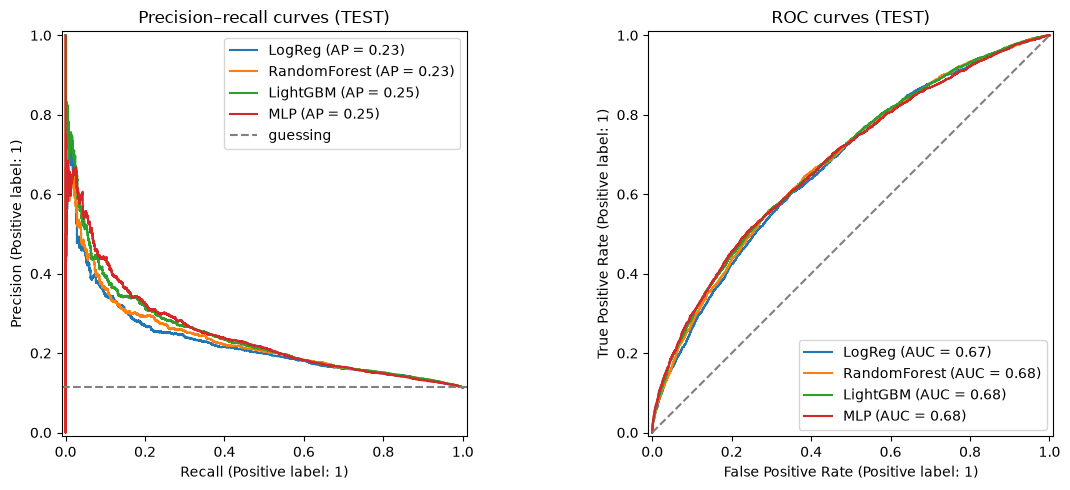

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for name, p in probs.items():
    PrecisionRecallDisplay.from_predictions(y_te, p, name=name, ax=axes[0])
    RocCurveDisplay.from_predictions(y_te, p, name=name, ax=axes[1])
axes[0].axhline(y_te.mean(), ls='--', color='grey', label='guessing')
axes[0].set_title('Precision–recall curves (TEST)')
axes[0].legend()
axes[1].plot([0, 1], [0, 1], ls='--', color='grey')
axes[1].set_title('ROC curves (TEST)')
plt.tight_layout()
plt.show()

The curves of the four models lie close together and well above the guessing lines. At the far left of the PR curve,
the few highest-risk patients are readmitted far more often than average, which is where a follow-up service gets the
most value.

---
## Step 5d — Choosing the final model

In [5]:
cv_table = pd.read_csv(RESULTS / 'cv_results.csv').set_index('model')
choice = test_table.set_index('model')
choice['CV PR-AUC (mean ± sd)'] = cv_table['PR-AUC']
choice['tuning time (s)'] = cv_table['seconds']
choice.loc['MLP', 'CV PR-AUC (mean ± sd)'] = (f"VAL {np.mean(mlp_out['seed_scores']):.3f} ± "
                                             f"{np.std(mlp_out['seed_scores']):.3f} (3 seeds)")
choice['interpretability'] = pd.Series({'LogReg': 'high (coefficients)', 'RandomForest': 'medium (SHAP)',
                                        'LightGBM': 'medium (SHAP)', 'MLP': 'low'})
choice

,PR-AUC,ROC-AUC,Brier,CV PR-AUC (mean ± sd),tuning time (s),interpretability
model,,,,,,
LogReg,"0.225 [0.211, 0.242]","0.673 [0.661, 0.685]","0.224 [0.222, 0.226]",0.212 ± 0.002,10.0,high (coefficients)
RandomForest,"0.233 [0.218, 0.250]","0.679 [0.668, 0.691]","0.177 [0.176, 0.179]",0.219 ± 0.003,121.0,medium (SHAP)
LightGBM,"0.246 [0.229, 0.263]","0.683 [0.671, 0.696]","0.095 [0.092, 0.098]",0.228 ± 0.004,251.0,medium (SHAP)
MLP,"0.248 [0.232, 0.267]","0.681 [0.669, 0.693]","0.202 [0.200, 0.204]",VAL 0.225 ± 0.005 (3 seeds),NaN,low


I choose **LightGBM**. The MLP is a hair higher on TEST PR-AUC, but the difference is far smaller than the confidence
intervals, so the two are effectively tied. When two options perform the same, I prefer the one that is easier to
trust and run: LightGBM had the best cross-validated score, it already gives honest probabilities, it trains in
minutes, and SHAP can explain it exactly. A clinician will want a reason with every flag, so explainability matters
here.

In [6]:
BEST = 'LightGBM'
best_model = final_models[BEST]

---
## Step 5e — Where does the model struggle?

A single overall score can hide weak spots, like an average exam mark that hides a failed topic. So I check the
PR-AUC of the final model inside a few groups of TEST patients.

In [7]:
p_best = probs[BEST]
stay = X_te['time_in_hospital']
slices = {
    'no previous inpatient stay': X_te['number_inpatient'] == 0,
    '1+ previous inpatient stays': X_te['number_inpatient'] >= 1,
    'short stay (1-3 days)': stay <= 3,
    'long stay (4+ days)': stay >= 4,
}
for grp in X_te['diag_1_grp'].value_counts().index:
    if (X_te['diag_1_grp'] == grp).sum() >= 100:
        slices[f'primary diagnosis: {grp}'] = X_te['diag_1_grp'] == grp

error_rows = []
for name, mask in slices.items():
    mask = mask.values
    error_rows.append({'group': name, 'n': int(mask.sum()),
                       'share readmitted': round(y_te[mask].mean(), 3),
                       'PR-AUC': round(average_precision_score(y_te[mask], p_best[mask]), 3)})
error_table = pd.DataFrame(error_rows)
error_table

,group,n,share readmitted,PR-AUC
0,no previous inpatient stay,13290,0.085,0.165
1,1+ previous inpatient stays,6483,0.172,0.310
2,short stay (1-3 days),9611,0.101,0.243
3,long stay (4+ days),10162,0.126,0.248
4,primary diagnosis: Circulatory,5980,0.116,0.210
5,primary diagnosis: Other,3521,0.104,0.258
6,primary diagnosis: Respiratory,2732,0.101,0.248
7,primary diagnosis: Digestive,1844,0.121,0.331
8,primary diagnosis: Diabetes,1730,0.129,0.288
9,primary diagnosis: Injury,1348,0.136,0.260


The clearest weak spot is **first-time patients**. For patients with no previous inpatient stay, PR-AUC is only about
0.17, against about 0.31 for patients who have been admitted before. Previous admissions are the model's strongest
clue, so when that clue is missing the model has much less to go on. It is like a doctor meeting a patient for the
first time without any notes.

Length of stay makes little difference. Among diagnosis groups, the model does best for digestive and diabetes
admissions and worst for genitourinary and circulatory ones.

---
## Step 6a — Can the risk scores be trusted? (calibration)

A risk score is **calibrated** when it means what it says: of 100 patients given "20% risk", about 20 really come back.
A weather forecaster who says "70% chance of rain" should see rain on about 70% of those days.

Class weighting usually breaks this. It tells the model "readmissions matter 8 times more", so the model shouts its
risk too loudly. Calibration learns a correction curve on VAL (data the model has never seen) that maps the raw
scores to honest probabilities. I use **isotonic regression**, a flexible step-shaped curve that only assumes "higher
raw score means higher real risk". VAL has about 12,000 patients, which is plenty for it.

In [8]:
def calibrate(model, X, y):
    try:
        from sklearn.frozen import FrozenEstimator
        cal = CalibratedClassifierCV(FrozenEstimator(model), method='isotonic')
    except ImportError:
        cal = CalibratedClassifierCV(model, method='isotonic', cv='prefit')
    return cal.fit(X, y)

cal = calibrate(best_model, X_val, y_val)

p_raw = best_model.predict_proba(X_te)[:, 1]
p_cal = cal.predict_proba(X_te)[:, 1]

calibration_table = pd.DataFrame({
    'version': ['raw (before calibration)', 'calibrated (isotonic)'],
    'Brier': [brier_score_loss(y_te, p_raw), brier_score_loss(y_te, p_cal)],
    'PR-AUC': [average_precision_score(y_te, p_raw), average_precision_score(y_te, p_cal)],
    'mean predicted risk': [p_raw.mean(), p_cal.mean()],
    'real share readmitted': [y_te.mean(), y_te.mean()],
}).round(4)
calibration_table

,version,Brier,PR-AUC,mean predicted risk,real share readmitted
0,raw (before calibration),0.0949,0.2458,0.1134,0.1135
1,calibrated (isotonic),0.0948,0.2303,0.1124,0.1135


The **reliability diagram** below puts predicted risk on the x-axis and what really happened on the y-axis. The dotted
diagonal is perfect honesty; points below it mean the model over-states risk.

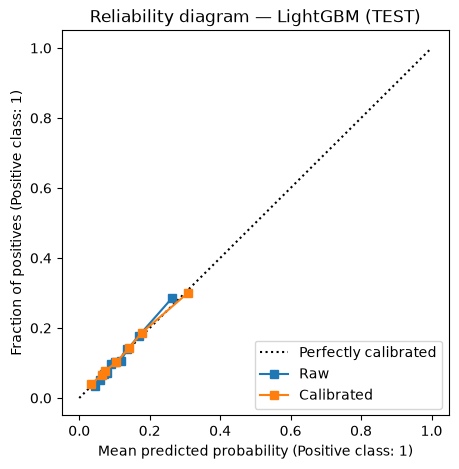

In [9]:
fig, ax = plt.subplots(figsize=(5, 5))
CalibrationDisplay.from_predictions(y_te, p_raw, n_bins=10, strategy='quantile', name='Raw', ax=ax)
CalibrationDisplay.from_predictions(y_te, p_cal, n_bins=10, strategy='quantile', name='Calibrated', ax=ax)
ax.set_title(f'Reliability diagram — {BEST} (TEST)')
plt.show()

Because my LightGBM chose no class weighting, its raw scores were already honest: the points sit on the diagonal
both before and after calibration, the average predicted risk (about 11%) matches the real rate, and the Brier score
barely changes. So calibration here works as a safety check that confirms the probabilities can be trusted.

Isotonic calibration is a step curve, so some patients end up sharing exactly the same score. That blurs the ranking
slightly, which is why PR-AUC drops a little (from about 0.25 to 0.23). I keep the calibrated scores for the decision
step anyway, because the threshold in Step 6c relies on the scores being honest probabilities.

---
## Step 6b — Where do I draw the line? (the cost-based threshold)

The model gives a risk; the hospital needs a yes/no: *call this patient after discharge or not.* There are two
possible mistakes:

| Mistake | What happens | Cost |
|---|---|---|
| **Missed readmission** (false negative) | the patient is not followed up and comes back to hospital | high: a readmission costs thousands |
| **Unnecessary call** (false positive) | a nurse calls a patient who would have been fine | low: some staff time |

A readmission costs far more than a phone call, but a call does not prevent every readmission. I therefore assume
that a missed readmission is **5 times** as costly as an unnecessary call (FN : FP = 5 : 1).

With honest probabilities, the best cut-off follows directly from the costs:

**threshold = cost of a false alarm / (cost of a false alarm + cost of a miss) = 1 / (1 + 5) ≈ 0.17**

In words: I call a patient when their risk is above about 17%. It is the same logic as taking an umbrella: if getting
soaked is 5 times worse than carrying an umbrella for nothing, I take it whenever the chance of rain is above about 1 in 6.

I check this against the data by plotting the average cost per patient for every possible cut-off on VAL.

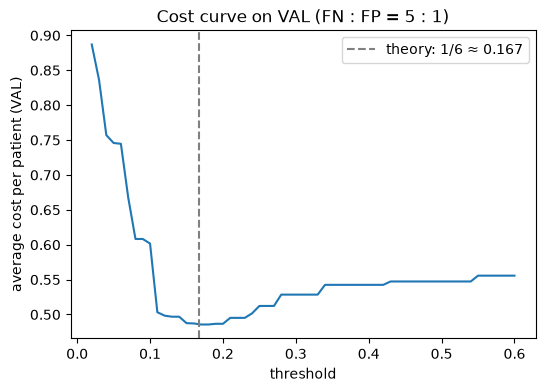

Lowest-cost threshold on VAL: 0.17


In [10]:
C_FN, C_FP = 5, 1

def exp_cost(y, pred, c_fn=C_FN, c_fp=C_FP):
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return (c_fn * fn + c_fp * fp) / len(y)

p_val_cal = cal.predict_proba(X_val)[:, 1]
thresholds = np.linspace(0.02, 0.6, 59)
costs = [exp_cost(y_val, (p_val_cal >= t).astype(int)) for t in thresholds]

plt.figure(figsize=(6, 4))
plt.plot(thresholds, costs)
plt.axvline(1 / 6, ls='--', color='grey', label='theory: 1/6 ≈ 0.167')
plt.xlabel('threshold')
plt.ylabel('average cost per patient (VAL)')
plt.title('Cost curve on VAL (FN : FP = 5 : 1)')
plt.legend()
plt.show()
print('Lowest-cost threshold on VAL:', round(thresholds[int(np.argmin(costs))], 3))

The lowest point of the cost curve on VAL is at about 0.17, exactly where the theory says it should be.

### How the threshold performs on TEST

A model is only worth using if it beats the two simplest policies: calling **nobody**, and calling **everybody**.

In [11]:
t = 1 / (1 + C_FN / C_FP)
pred = (p_cal >= t).astype(int)

def threshold_report(y, p, t, c_fn=C_FN, c_fp=C_FP):
    pred = (p >= t).astype(int)
    return {'threshold': round(t, 3),
            'recall': round(recall_score(y, pred, zero_division=0), 3),
            'precision': round(precision_score(y, pred, zero_division=0), 3),
            'alert rate': round(pred.mean(), 3),
            'expected cost': round(exp_cost(y, pred, c_fn, c_fp), 4)}

threshold_table = pd.DataFrame([
    {'policy': f'{BEST}, calibrated, threshold 1/6', **threshold_report(y_te, p_cal, t)},
    {'policy': 'call nobody', **threshold_report(y_te, p_cal, 1.01)},
    {'policy': 'call everybody', **threshold_report(y_te, p_cal, 0.0)},
])
threshold_table

,policy,threshold,recall,precision,alert rate,expected cost
0,"LightGBM, calibrated, threshold 1/6",0.167,0.302,0.269,0.127,0.4895
1,call nobody,1.010,0.000,0.000,0.000,0.5674
2,call everybody,0.000,1.000,0.113,1.000,0.8865


At this threshold the model flags about **13%** of patients. It catches about **30%** of all real readmissions, and
about **27%** of the flagged patients really come back, more than twice the 11% base rate. Its average cost per
patient (about 0.49) is lower than calling nobody (about 0.57) and far lower than calling everybody (about 0.89), so
the model adds value.

### Step 6c — What if my cost assumption is wrong?

The 5 : 1 ratio is an assumption, so I repeat the calculation for 3 : 1 and 10 : 1. Each row uses its own costs and
its own threshold.

In [12]:
sens_rows = []
for ratio in [3, 5, 10]:
    sens_rows.append({'FN : FP': f'{ratio} : 1',
                      **threshold_report(y_te, p_cal, 1 / (1 + ratio), c_fn=ratio, c_fp=1),
                      'cost: call nobody': round(ratio * y_te.mean(), 4),
                      'cost: call everybody': round(1 - y_te.mean(), 4)})
sensitivity_table = pd.DataFrame(sens_rows)
sensitivity_table

,FN : FP,threshold,recall,precision,alert rate,expected cost,cost: call nobody,cost: call everybody
0,3 : 1,0.250,0.148,0.342,0.049,0.3224,0.3405,0.8865
1,5 : 1,0.167,0.302,0.269,0.127,0.4895,0.5674,0.8865
2,10 : 1,0.091,0.783,0.153,0.580,0.7385,1.1349,0.8865


The model beats both simple policies at every ratio, so the conclusion does not hinge on my exact assumption.
What changes is the size of the follow-up list: at 3 : 1 only about 5% of patients are flagged, while at 10 : 1 more
than half are, catching about 78% of readmissions. In practice the ratio would be set together with the hospital,
based on its real costs and staff capacity.

---
## Step 7 — Why does the model say what it says? (SHAP)

SHAP splits each prediction into contributions from each feature. Think of a team's final score: SHAP shares the
points fairly between the players. For one patient it might say: start from the average risk; "3 previous inpatient
stays" added a lot; "discharged home" took a little away. Averaging these shares over many patients shows which
features matter most overall.

I explain 2,000 random TEST patients, which is enough for a clear picture and quick to compute. SHAP explains the
model's raw scores (before calibration) in log-odds units. Calibration keeps the ranking almost the same, so the
explanation still describes what drives the ranking. I show the original (unscaled) values in the plots, so
"number_inpatient = 3" really means 3 previous stays.

In [13]:
pre_fitted = best_model.named_steps['pre']
clf = best_model.named_steps['clf']

Xs = X_te.sample(2000, random_state=SEED)
Xt = pre_fitted.transform(Xs)
Xt = Xt.toarray() if hasattr(Xt, 'toarray') else Xt
names = [n.split('__', 1)[1] for n in pre_fitted.get_feature_names_out()]
Xt = pd.DataFrame(Xt, columns=names)

if BEST == 'LogReg':
    explainer = shap.LinearExplainer(clf, Xt)
else:
    explainer = shap.TreeExplainer(clf)
sv = explainer(Xt)
if len(sv.shape) == 3:
    sv = sv[:, :, 1]

# I show real values (e.g. 3 stays) in the plots instead of the scaled ones the model sees
display_values = Xt.copy()
display_values[num_cols] = Xs[num_cols].values
sv.data = display_values.values

### The big picture: the beeswarm plot

Each row is a feature, the most important at the top. Each dot is one patient. Dots to the right of zero push risk
**up**; dots to the left push it **down**. The colour shows the feature's value (red = high, blue = low), so "red dots
on the right" means high values increase risk.

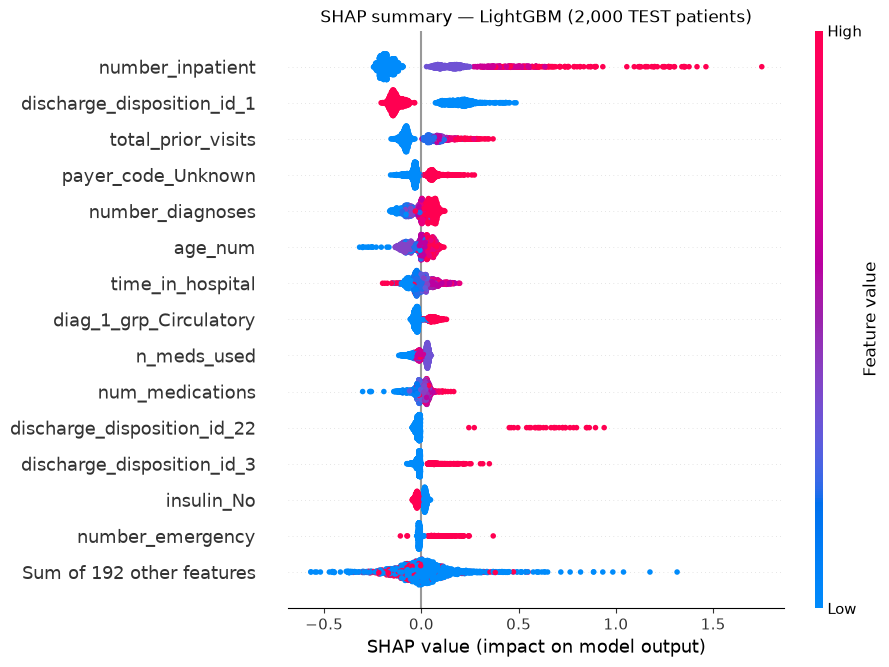

In [14]:
shap.plots.beeswarm(sv, max_display=15, show=False)
plt.title(f'SHAP summary — {BEST} (2,000 TEST patients)')
plt.show()

### The top features in a table

The names of one-hot features read as `column_value`. For example `discharge_disposition_id_1` means "discharged home"
(code 1 in the code book), and `payer_code_Unknown` means "payer not recorded".

In [15]:
shap_values = pd.DataFrame(sv.values, columns=names)
importance = shap_values.abs().mean().sort_values(ascending=False).head(10)
direction = {f: np.corrcoef(Xt[f], shap_values[f])[0, 1] for f in importance.index}

top_features = pd.DataFrame({
    'mean |SHAP|': importance.round(4),
    'higher value →': ['raises risk' if direction[f] > 0 else 'lowers risk' for f in importance.index],
})
top_features

,mean |SHAP|,higher value →
number_inpatient,0.2298,raises risk
discharge_disposition_id_1,0.1583,lowers risk
total_prior_visits,0.0896,raises risk
payer_code_Unknown,0.0523,raises risk
number_diagnoses,0.0508,raises risk
age_num,0.0466,raises risk
time_in_hospital,0.0427,raises risk
diag_1_grp_Circulatory,0.0370,raises risk
n_meds_used,0.0298,raises risk
num_medications,0.0283,raises risk


The explanation makes clinical sense:

- **Previous inpatient stays** (`number_inpatient`) are by far the strongest driver: the more often a patient was
  admitted in the past year, the higher the risk. This is also the best-known predictor in the readmission literature.
- **Discharged home** lowers risk. Patients who go to care homes or other facilities are usually frailer.
- **Total previous visits**, **number of diagnoses**, **age** and **length of stay** all raise risk when they are
  higher. They all describe a sicker, more complex patient.
- **`payer_code_Unknown`** also appears. A missing payer is an administrative detail, not a medical one, so the model
  may be picking up something about how or where patients were recorded. This is a reminder to check fairness (Step 8).

SHAP shows what the model *uses*, which is association, not cause. It does not mean that changing a feature would
change a patient's real risk.

### One patient: why were they flagged?

The waterfall plot explains the highest-risk patient in the sample. It starts at the bottom from the average score and
adds each feature's push until it reaches this patient's score at the top.

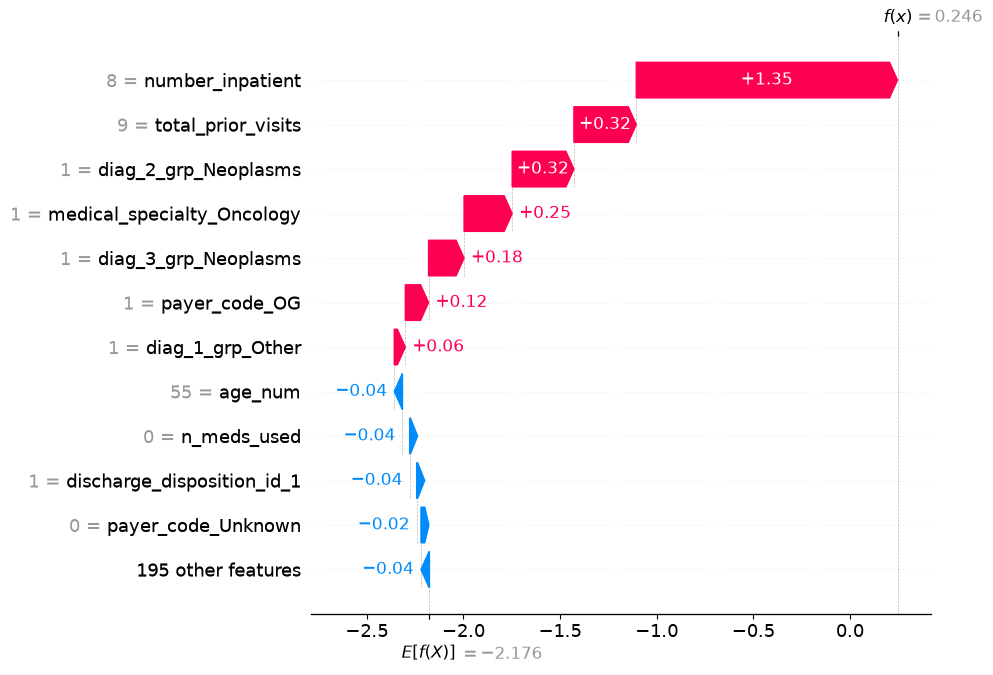

In [16]:
i = int(np.argmax(best_model.predict_proba(Xs)[:, 1]))
shap.plots.waterfall(sv[i], max_display=12, show=False)
plt.show()

This patient, aged 50–60, was flagged mainly because of **8 inpatient stays in the past year** (9 hospital visits in total), which give by far the biggest push.
Cancer-related information adds more: secondary diagnoses in the *Neoplasms* group and an *Oncology* specialty.
A clinician could read this as "frequent recent admissions in a patient with cancer", which is a sensible reason to
arrange follow-up. This is how the explanation would be shown next to each flag in practice.

---
## Step 8 — Is the model fair?

I check whether the model, at my threshold, treats groups of patients equally. I look at race, gender and age, with
three measures:

| Measure | The question it answers |
|---|---|
| **TPR** (true positive rate, recall) | Of the patients who really came back, what share did I catch in each group? |
| **FPR** (false positive rate) | Of the patients who did not come back, what share did I flag by mistake? |
| **Selection rate** | What share of each group gets a follow-up call? |

TPR matters most here. If the model catches fewer real readmissions in one group, that group quietly receives less
follow-up care. Equal TPR across groups is called **equal opportunity**.

In [17]:
FAIR_METRICS = {'n': count, 'TPR': true_positive_rate, 'FPR': false_positive_rate,
                'selection rate': selection_rate}

def audit(pred, column):
    return MetricFrame(metrics=FAIR_METRICS, y_true=y_te, y_pred=pred,
                       sensitive_features=sens_te[column])

for column in ['race', 'gender', 'age_band']:
    mf = audit(pred, column)
    print(f'\n{column}')
    display(mf.by_group.round(3))
    print('Largest gap:', mf.difference()[['TPR', 'FPR', 'selection rate']].round(3).to_dict())


race


,n,TPR,FPR,selection rate
race,,,,
AfricanAmerican,3697.0,0.288,0.121,0.139
Asian,116.0,0.100,0.075,0.078
Caucasian,14813.0,0.308,0.104,0.128
Hispanic,398.0,0.389,0.080,0.108
Other,302.0,0.290,0.063,0.086
Unknown,447.0,0.125,0.065,0.069


Largest gap: {'TPR': 0.289, 'FPR': 0.058, 'selection rate': 0.069}

gender


,n,TPR,FPR,selection rate
gender,,,,
Female,10726.0,0.317,0.108,0.132
Male,9047.0,0.283,0.102,0.122


Largest gap: {'TPR': 0.033, 'FPR': 0.006, 'selection rate': 0.01}



age_band


,n,TPR,FPR,selection rate
age_band,,,,
40-60,5376.0,0.330,0.087,0.112
60-80,9277.0,0.291,0.108,0.129
80+,3831.0,0.225,0.116,0.129
<40,1289.0,0.503,0.131,0.176


Largest gap: {'TPR': 0.278, 'FPR': 0.044, 'selection rate': 0.064}


**Race.** The two large groups are treated very similarly: the model catches about 29% of readmissions among African
American patients and about 31% among Caucasian patients. The biggest-looking gaps come from very small groups, such as
Asian patients, where only 10 TEST patients were readmitted.

**Gender.** Women and men are close (about 32% vs 28% caught).

**Age.** This is the clearest gap. The model catches about half of the readmissions in patients under 40, but only
about 22% in patients over 80, while false alarms are similar across ages. Older patients are the largest and often the
most fragile group, so this gap deserves attention.

### How sure am I about the small groups?

With only a handful of readmitted patients, a group's TPR can swing a lot by chance, like judging a football player on
three penalty kicks. The error bars below show the 95% bootstrap range for each race group.

,race,n,readmitted,TPR,low,high
0,AfricanAmerican,3697,399,0.288,0.243,0.332
1,Asian,116,10,0.100,0.000,0.333
2,Caucasian,14813,1736,0.308,0.286,0.330
3,Hispanic,398,36,0.389,0.239,0.538
4,Other,302,31,0.290,0.133,0.482
5,Unknown,447,32,0.125,0.025,0.263


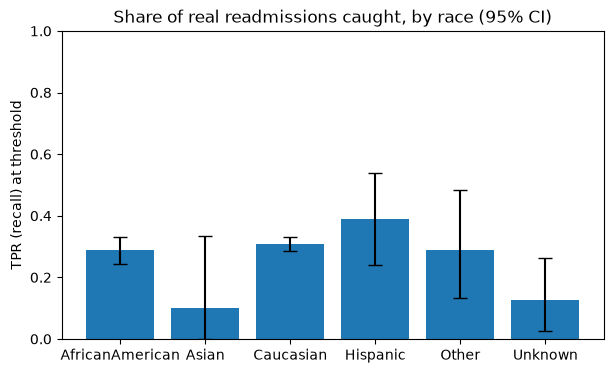

In [18]:
pred_s = pd.Series(pred, index=y_te.index)
tpr_rows = []
for group, idx in sens_te.groupby('race').groups.items():
    yt, pr = y_te.loc[idx], pred_s.loc[idx]
    lo, hi = boot_ci(yt, pr, lambda a, b: recall_score(a, b, zero_division=0))
    tpr_rows.append({'race': group, 'n': len(idx), 'readmitted': int(yt.sum()),
                     'TPR': recall_score(yt, pr, zero_division=0), 'low': lo, 'high': hi})
tpr_table = pd.DataFrame(tpr_rows).round(3)
display(tpr_table)

plt.figure(figsize=(7, 4))
plt.bar(tpr_table['race'], tpr_table['TPR'],
        yerr=[tpr_table['TPR'] - tpr_table['low'], tpr_table['high'] - tpr_table['TPR']], capsize=5)
plt.ylabel('TPR (recall) at threshold')
plt.ylim(0, 1)
plt.title('Share of real readmissions caught, by race (95% CI)')
plt.show()

The error bars for African American and Caucasian patients are narrow and overlap. For the small groups they are very
wide: the Asian group's range runs from 0 to about a third. I cannot say whether those groups are really treated
differently; I would need more data to tell.

---
## Step 8d — Fix A: removing race from the inputs

The simplest fix is to stop showing the model the patient's race and retrain it with the same settings
("fairness through unawareness"). I keep race in the separate audit table so I can still measure the gaps.

In [19]:
def make_preprocessor(cat_cols, num_cols):
    num_pipe = Pipeline([('imp', SimpleImputer(strategy='median')),
                         ('sc', StandardScaler())])
    cat_pipe = Pipeline([('imp', SimpleImputer(strategy='constant', fill_value='Missing')),
                         ('oh', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=50))])
    return ColumnTransformer([('num', num_pipe, num_cols),
                              ('cat', cat_pipe, cat_cols)])

cat_no_race = [c for c in cat_cols if c != 'race']
model_nr = Pipeline([('pre', make_preprocessor(cat_no_race, num_cols)),
                     ('clf', clone(clf))])
model_nr.fit(X_fit.drop(columns='race'), y_fit)
cal_nr = calibrate(model_nr, X_val.drop(columns='race'), y_val)

p_cal_nr = cal_nr.predict_proba(X_te.drop(columns='race'))[:, 1]
pred_nr = (p_cal_nr >= t).astype(int)
print('TEST PR-AUC without race:', round(average_precision_score(y_te, p_cal_nr), 3))

TEST PR-AUC without race: 0.231


---
## Step 8d — Fix B: a separate threshold for each race group

A stronger fix is fairlearn's `ThresholdOptimizer`. It learns on VAL a different cut-off for each race group, chosen so
that every group gets roughly the same TPR. The catch: it needs to know each patient's race at the moment of the
decision, and it replaces my cost-based threshold with its own goal (balanced accuracy).

In [20]:
thr_opt = ThresholdOptimizer(estimator=cal, constraints='true_positive_rate_parity',
                             objective='balanced_accuracy_score', prefit=True,
                             predict_method='predict_proba')
thr_opt.fit(X_val, y_val, sensitive_features=X_val['race'])
pred_fair = thr_opt.predict(X_te, sensitive_features=sens_te['race'], random_state=SEED)

audit(pred_fair, 'race').by_group.round(3)

,n,TPR,FPR,selection rate
race,,,,
AfricanAmerican,3697.0,0.521,0.258,0.286
Asian,116.0,0.000,0.038,0.034
Caucasian,14813.0,0.548,0.297,0.327
Hispanic,398.0,0.417,0.108,0.136
Other,302.0,0.484,0.244,0.268
Unknown,447.0,0.656,0.373,0.394


---
## Step 8e — Before and after: what did the fixes cost?

I compare the original model with both fixes. I show two race gaps:
- **TPR gap (race)** — the largest gap across *all* race groups. The tiny groups make this number jumpy.
- **TPR gap (race, big groups)** — the gap between the groups with at least 100 readmitted TEST patients (African
  American and Caucasian). This is the gap I can trust most.

In [21]:
readmitted_per_race = y_te.groupby(sens_te['race']).sum()
BIG_RACE_GROUPS = list(readmitted_per_race[readmitted_per_race >= 100].index)

def summary_row(version, pred, p=None):
    race, age = audit(pred, 'race').difference(), audit(pred, 'age_band').difference()
    tpr_big = audit(pred, 'race').by_group.loc[BIG_RACE_GROUPS, 'TPR']
    return {'version': version,
            'PR-AUC': round(average_precision_score(y_te, p), 3) if p is not None else 'n/a (yes/no only)',
            'recall': round(recall_score(y_te, pred), 3),
            'alert rate': round(pred.mean(), 3),
            'expected cost': round(exp_cost(y_te, pred), 4),
            'TPR gap (race)': round(race['TPR'], 3),
            'TPR gap (race, big groups)': round(tpr_big.max() - tpr_big.min(), 3),
            'FPR gap (race)': round(race['FPR'], 3),
            'TPR gap (age)': round(age['TPR'], 3)}

before_after = pd.DataFrame([
    summary_row(f'Original {BEST}', pred, p_cal),
    summary_row('A: race removed', pred_nr, p_cal_nr),
    summary_row('B: group thresholds (race)', pred_fair),
])
before_after

,version,PR-AUC,recall,alert rate,expected cost,TPR gap (race),"TPR gap (race, big groups)",FPR gap (race),TPR gap (age)
0,Original LightGBM,0.23,0.302,0.127,0.4895,0.289,0.019,0.058,0.278
1,A: race removed,0.231,0.299,0.127,0.4908,0.295,0.013,0.055,0.278
2,B: group thresholds (race),n/a (yes/no only),0.539,0.314,0.5146,0.656,0.027,0.336,0.149


**Fix A (race removed)** costs almost nothing: PR-AUC and cost are unchanged. But it also changes the gaps very little.
The model can still pick up similar information from other columns, such as payer, admission source and previous
visits. These act as *proxies*, like guessing someone's neighbourhood from their postcode even when the address is
hidden. So hiding race on its own does not make a model fair. Fix A is still worth keeping: it uses less sensitive
data, which fits the data-minimisation principle of UK GDPR.

**Fix B (group thresholds)** does not help here. It flags far more patients (about 31% instead of 13%), raises the
average cost, and does not shrink the trustworthy big-group gap. The all-groups gap even grows, because the per-group
cut-offs for the tiny groups were learned from only a handful of readmitted VAL patients and are unreliable. It would
also require using race directly in a clinical decision, which is legally and ethically sensitive.

**My conclusion:** for the two large race groups the original model is already close to fair (a gap of about
2 percentage points). The larger gaps sit in groups too small to measure reliably, and in **age**, where older
patients' readmissions are caught less often. I keep Fix A (dropping race) as a low-cost improvement, and I would
monitor the age gap and the small groups as more data arrives.